# Phase 5: Injury analysis (pattern evaluation)

**Question:** do players in teams with different playing styles get injured differently: how often, how badly
(days lost) and where on the body; and how does this change over seasons and differ between leagues?

**Unit:** the **player-club-season** (Phase 2 membership: ≥ 1 appearance or marked injured), with its team's style
(Phase 4, k = 7; k = 4 as a check). Injuries are those lasting more than 7 days (Phase 2).

**Methods** (descriptive, as the course allows):
- **Rates:** injuries per player-season, injuries per 1,000 minutes, days lost per player-season, share severe.
- **League-adjusted rate ratio (RR):** Transfermarkt records injuries at very different rates per league, so each
  group's injuries are compared with what its players would have at their **league's average rate** (indirect
  standardisation): RR = observed / expected. RR 1.2 = 20% more than the league average. A stricter version uses
  the average of league × age band × position.
- **95% confidence intervals:** bootstrap over **team-seasons** (players of one squad share coaches, medical staff
  and schedule, so they are not independent), 1,000 resamples, fixed seed.
- **Tests:** chi-square for the body-area mix (with Cramér's V as effect size) and for observed vs expected injuries.

**Steps**
1. Player-season table
2. Rate and bootstrap helpers; league baselines
3. Injury frequency and days lost by style
4. Body areas by style
5. Seasons: injury trend and style shares over time
6. Leagues: rates, body areas, style effect within each league
7. Age and position: is it the squad mix?
8. Team strength and workload
9. Fitness absences (secondary outcome)
10. Sensitivity checks
11. Report

**Inputs:** `data/02_injuries/`, `data/03_features/`, `data/04_clusters/`, `tm_squads`, `us_team_matches`.
**Outputs:** `data/05_injury_analysis/`, `reports/05_injury_analysis.md`, `reports/figures/05_*.png`.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2, chi2_contingency

sys.path.insert(0, str(Path.cwd().parent))  # project root, for the analysis package
from analysis.config import DATA_DIR, FIGURES_DIR, REPORTS_DIR, SEASONS, phase_dir
from analysis.load import league_from_understat, read_table, season_key
from analysis.report import md_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

PHASE = "05_injury_analysis"
OUT_DIR = phase_dir(PHASE)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
N_BOOT = 1000
AGE_BANDS = [0, 21, 25, 29, 99]  # ≤ 21, 22–25, 26–29, 30+ (age on 1 January of the season)
AGE_LABELS = ["≤21", "22–25", "26–29", "30+"]
COVID_SEASONS = ["2019-20", "2020-21"]
LEAGUES = ["Premier League", "La Liga", "Serie A", "Bundesliga", "Ligue 1"]

# Chart palette: validated reference palette (dataviz skill), categorical slots in fixed order by style.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
})


def save(fig, name: str) -> str:
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    return name

## Step 1. Player-season table

One row per player-club-season with: league, season, club, team style (k = 7 and k = 4), team strength (points per
match), team workload (Phase 3 exposure features), the player's age band and position, minutes in all competitions,
and his injuries at that club that season (count, days lost, severe, by body area, with surgery), plus mild injuries
(4–7 days) and fitness absences for the sensitivity check and the secondary outcome.

In [2]:
members = pd.read_parquet(DATA_DIR / "02_injuries" / "player_club_seasons.parquet")
injuries = pd.read_parquet(DATA_DIR / "02_injuries" / "injuries_clean.parquet")
mild = pd.read_parquet(DATA_DIR / "02_injuries" / "injuries_mild.parquet")
non_inj = pd.read_parquet(DATA_DIR / "02_injuries" / "non_injuries.parquet")
clusters = pd.read_parquet(DATA_DIR / "04_clusters" / "team_season_clusters.parquet").rename(columns={"tm_club_id": "club_id"})
features = pd.read_parquet(DATA_DIR / "03_features" / "team_season_features.parquet").rename(columns={"tm_club_id": "club_id"})
roles = pd.read_csv(DATA_DIR / "03_features" / "feature_roles.csv")
EXPOSURE = roles[(roles.role == "exposure") & (roles.status == "kept")].feature.tolist()

# Team strength: league points per match (Understat).
um = read_table("us_team_matches")
points = (um.assign(league=um.league.map(league_from_understat), season=um.season.astype(int), pts=um.pts.astype(float))
          .groupby(["league", "season", "team_id"]).pts.mean().rename("points_pm").reset_index().rename(columns={"team_id": "us_team_id"}))
keys = pd.read_csv(DATA_DIR / "01_entities" / "team_seasons.csv", dtype={"tm_club_id": str, "us_team_id": str}).rename(columns={"tm_club_id": "club_id"})
team = (clusters.merge(keys[["league", "season", "club_id", "us_team_id"]], on=["league", "season", "club_id"])
        .merge(points, on=["league", "season", "us_team_id"]).merge(features[["league", "season", "club_id"] + EXPOSURE], on=["league", "season", "club_id"]))
team["strength"] = pd.qcut(team.points_pm, 3, labels=["weaker third", "middle third", "stronger third"])
assert len(team) == 1170

# Player attributes: position (constant per player) and age on 1 January of the season.
sq = read_table("tm_squads")
player = sq[["playerId", "position_group", "date_of_birth"]].replace("", np.nan).groupby("playerId").first()
ps = members.merge(team.drop(columns=["club", "season_key", "us_team_id"]), on=["league", "season", "club_id"], how="left")
ps = ps.join(player, on="playerId")
dob = pd.to_datetime(ps.date_of_birth, errors="coerce")
ps["age"] = ((pd.to_datetime((ps.season + 1).astype(str) + "-01-01") - dob).dt.days / 365.25).round(1)
ps["age_band"] = pd.cut(ps.age, AGE_BANDS, labels=AGE_LABELS)
ps["position"] = ps.position_group.str.title()

# Injuries per player-club-season.
KEY = ["playerId", "club_id", "season"]
inj = injuries.assign(severe=injuries.severity.str.startswith("severe"), surgery=injuries.surgery.astype(bool))
agg = inj.groupby(KEY).agg(injuries=("days", "size"), days_lost=("days", "sum"), severe=("severe", "sum"), surgeries=("surgery", "sum"))
areas = pd.crosstab([inj.playerId, inj.club_id, inj.season], inj.body_area).add_prefix("area: ")
mild_n = mild.groupby(KEY).size().rename("mild_injuries")
fit_n = non_inj[non_inj.non_injury_reason == "fitness"].groupby(KEY).size().rename("fitness_absences")
ps = ps.join(agg, on=KEY).join(areas, on=KEY).join(mild_n, on=KEY).join(fit_n, on=KEY)
count_cols = ["injuries", "days_lost", "severe", "surgeries", "mild_injuries", "fitness_absences"] + list(areas.columns)
ps[count_cols] = ps[count_cols].fillna(0).astype(int)
ps["team_season"] = ps.league + " " + ps.season_key + " " + ps.club_id

# Checks: every injury lands on exactly one player-season; every player-season has a style.
assert ps.cluster_name.notna().all()
assert ps.injuries.sum() == len(injuries), (ps.injuries.sum(), len(injuries))
ps.to_parquet(OUT_DIR / "player_seasons.parquet", index=False)
pd.Series({
    "player-club-seasons": len(ps), "players": ps.playerId.nunique(), "team-seasons": ps.team_season.nunique(),
    "injuries > 7 days": int(ps.injuries.sum()), "days lost": int(ps.days_lost.sum()),
    "mild injuries (4–7 days)": int(ps.mild_injuries.sum()), "fitness absences": int(ps.fitness_absences.sum()),
    "missing age": int(ps.age.isna().sum()), "missing position": int(ps.position.isna().sum()),
}, name="count").to_frame()

,count
player-club-seasons,36525
players,10340
team-seasons,1170
injuries > 7 days,24581
days lost,1113471
mild injuries (4–7 days),5180
fitness absences,953
missing age,21
missing position,0


## Step 2. Rate and bootstrap helpers; league baselines

`summarise(df, by)` gives, per group: player-seasons, injuries, the four rates and the league-adjusted rate ratios
(frequency and days lost) with bootstrap 95% CIs. The bootstrap resamples **team-seasons** within each group.

League baseline: each league's average injuries and days lost per player-season over all 12 seasons (the decision of
Phase 0). The stricter baseline uses league × age band × position.

In [3]:
def add_expected(df: pd.DataFrame, strata: list[str], suffix: str = "") -> pd.DataFrame:
    """Expected injuries and days lost per player-season from the mean of its stratum."""
    means = df.groupby(strata, observed=True)[["injuries", "days_lost"]].transform("mean")
    return df.assign(**{f"exp_inj{suffix}": means.injuries, f"exp_days{suffix}": means.days_lost})


ps = add_expected(ps, ["league"])
lap = ps.dropna(subset=["age_band", "position"]).copy()
lap = add_expected(lap, ["league", "age_band", "position"], "_lap")
ps = ps.join(lap[["exp_inj_lap", "exp_days_lap"]])
rng = np.random.default_rng(SEED)


def boot_ratio(teams: pd.DataFrame, num: str, den: str) -> tuple[float, float]:
    """95% CI of sum(num) / sum(den), resampling team-seasons."""
    n, v_num, v_den = len(teams), teams[num].to_numpy(), teams[den].to_numpy()
    idx = rng.integers(0, n, (N_BOOT, n))
    ratios = v_num[idx].sum(axis=1) / v_den[idx].sum(axis=1)
    return tuple(np.percentile(ratios, [2.5, 97.5]))


def summarise(df: pd.DataFrame, by: str | list[str], adjust: str = "") -> pd.DataFrame:
    by = [by] if isinstance(by, str) else by
    cols = ["injuries", "days_lost", "severe", "minutes", f"exp_inj{adjust}", f"exp_days{adjust}"]
    teams = df.assign(ps=1).groupby(by + ["team_season"], observed=True)[cols + ["ps"]].sum().reset_index()
    rows = []
    for key, t in teams.groupby(by, observed=True):
        rr_lo, rr_hi = boot_ratio(t, "injuries", f"exp_inj{adjust}")
        dr_lo, dr_hi = boot_ratio(t, "days_lost", f"exp_days{adjust}")
        tot = t[cols + ["ps"]].sum()
        rows.append(dict(zip(by, key if isinstance(key, tuple) else (key,))) | {
            "player-seasons": int(tot.ps), "team-seasons": len(t), "injuries": int(tot.injuries),
            "injuries / player-season": tot.injuries / tot.ps,
            "per 1,000 min": 1000 * tot.injuries / tot.minutes,
            "days lost / player-season": tot.days_lost / tot.ps,
            "severe share": tot.severe / tot.injuries if tot.injuries else np.nan,
            "RR": tot.injuries / tot[f"exp_inj{adjust}"], "RR low": rr_lo, "RR high": rr_hi,
            "days RR": tot.days_lost / tot[f"exp_days{adjust}"], "days RR low": dr_lo, "days RR high": dr_hi,
        })
    return pd.DataFrame(rows).set_index(by)


def fmt(table: pd.DataFrame) -> pd.DataFrame:
    """Rounded, with CIs written as 'RR (low–high)'."""
    t = table.copy()
    t["RR (95% CI)"] = t.apply(lambda r: f"{r['RR']:.2f} ({r['RR low']:.2f}–{r['RR high']:.2f})", axis=1)
    t["days RR (95% CI)"] = t.apply(lambda r: f"{r['days RR']:.2f} ({r['days RR low']:.2f}–{r['days RR high']:.2f})", axis=1)
    t = t.drop(columns=["RR", "RR low", "RR high", "days RR", "days RR low", "days RR high"])
    return t.round({"injuries / player-season": 3, "per 1,000 min": 3, "days lost / player-season": 1, "severe share": 3})


def gof_test(df: pd.DataFrame, by: str, adjust: str = "") -> tuple[float, int, float]:
    """Chi-square of observed vs expected injuries across groups (Poisson assumption; injuries are overdispersed, so
    the bootstrap CIs are the main evidence)."""
    g = df.groupby(by, observed=True)[["injuries", f"exp_inj{adjust}"]].sum()
    stat = (((g.injuries - g[f"exp_inj{adjust}"]) ** 2) / g[f"exp_inj{adjust}"]).sum()
    dof = len(g) - 1
    return stat, dof, chi2.sf(stat, dof)


baseline = ps.groupby("league")[["injuries", "days_lost"]].mean().rename(
    columns={"injuries": "injuries / player-season", "days_lost": "days lost / player-season"}).round(3)
baseline

,injuries / player-season,days lost / player-season
league,,
Bundesliga,0.790,37.701
La Liga,0.599,26.938
Ligue 1,0.466,21.539
Premier League,0.685,36.235
Serie A,0.823,30.419


## Step 3. Injury frequency and days lost by style

The core comparison: for each of the seven styles, raw rates and the league-adjusted rate ratios for frequency and
for days lost, with 95% CIs. An RR whose CI excludes 1 differs from the league average.

In [4]:
STYLE_ORDER = (clusters.drop_duplicates("cluster").sort_values("cluster").cluster_name.tolist())
by_style = summarise(ps, "cluster_name").loc[STYLE_ORDER]
by_style_lap = summarise(ps.dropna(subset=["exp_inj_lap"]), "cluster_name", "_lap").loc[STYLE_ORDER]
style_test = gof_test(ps, "cluster_name")
print(f"observed vs expected across styles: chi² = {style_test[0]:.1f}, df = {style_test[1]}, p = {style_test[2]:.2g}")
fmt(by_style)

observed vs expected across styles: chi² = 306.4, df = 6, p = 3.5e-63


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
cluster_name,,,,,,,,,
Aggressive press and set pieces,5454,178,3377,0.619,0.438,30.1,0.461,0.97 (0.91–1.04),1.04 (0.96–1.12)
Controlled possession,5370,175,3972,0.740,0.464,31.4,0.434,1.14 (1.08–1.20),1.06 (1.00–1.13)
Direct and physical,5567,178,3367,0.605,0.448,26.9,0.459,0.90 (0.85–0.95),0.94 (0.88–1.00)
Back three,5313,166,3918,0.737,0.537,30.4,0.392,1.00 (0.94–1.04),0.97 (0.91–1.03)
Counter-attacking,4196,132,2463,0.587,0.461,29.3,0.490,0.89 (0.83–0.95),0.97 (0.90–1.05)
Elite dominance,3587,114,3009,0.839,0.504,35.3,0.417,1.25 (1.17–1.32),1.08 (1.01–1.17)
Passive low block,7038,227,4475,0.636,0.473,31.3,0.485,0.95 (0.89–1.00),0.97 (0.91–1.04)


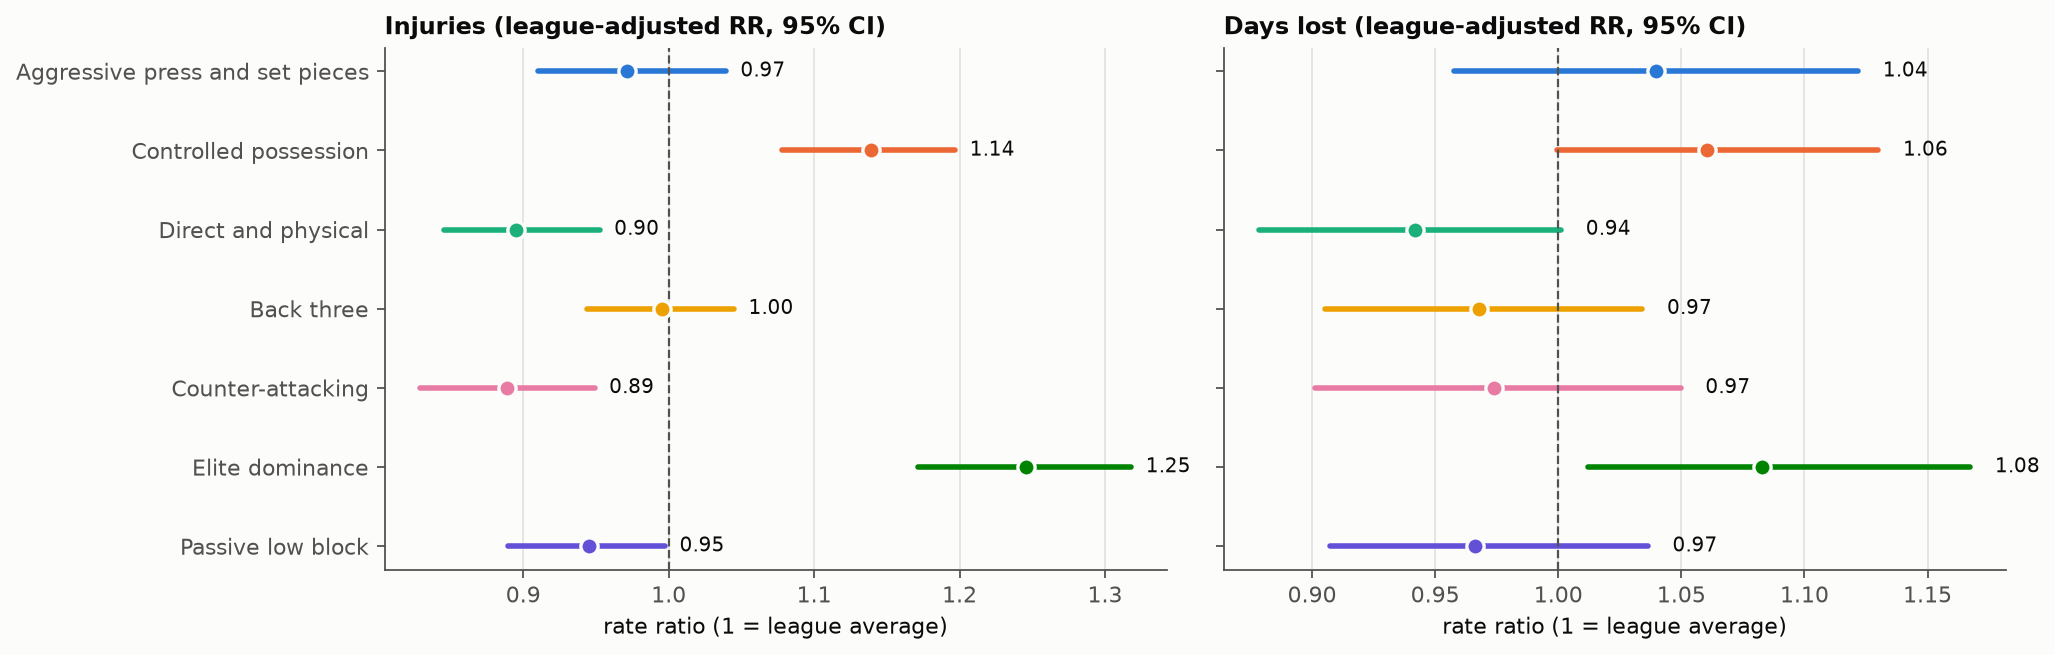

In [5]:
# Figure: league-adjusted rate ratios with 95% CIs, frequency and days lost, one row per style.
def ci_plot(ax, table: pd.DataFrame, rr: str, lo: str, hi: str, title: str) -> None:
    y = np.arange(len(table))[::-1]
    for yi, (name, r), color in zip(y, table.iterrows(), SERIES):
        ax.plot([r[lo], r[hi]], [yi, yi], color=color, linewidth=2.5, solid_capstyle="round")
        ax.scatter(r[rr], yi, s=60, color=color, edgecolors=SURFACE, linewidths=1.5, zorder=3)
        ax.text(r[hi] + 0.01, yi, f"{r[rr]:.2f}", va="center", fontsize=9, color=INK)
    ax.axvline(1, color=MUTED, linewidth=1, linestyle="--")
    ax.set_yticks(y, table.index)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
ci_plot(axes[0], by_style, "RR", "RR low", "RR high", "Injuries (league-adjusted RR, 95% CI)")
ci_plot(axes[1], by_style, "days RR", "days RR low", "days RR high", "Days lost (league-adjusted RR, 95% CI)")
for ax in axes:
    ax.set_xlabel("rate ratio (1 = league average)")
fig.tight_layout()
style_fig = save(fig, "05_rates_by_style.png")

## Step 4. Body areas by style

Share of each style's injuries per body area. *Unknown* is shown but left out of the test, since its share depends on
recording. Chi-square tests whether the body-area mix differs by style; Cramér's V says how much (0 = not at all,
0.1 small, 0.3 medium). Standardised residuals show which cells drive it (beyond ±2 = notably more or fewer injuries
there than if the mix were the same for every style).

In [6]:
AREA_COLS = [c for c in ps.columns if c.startswith("area: ")]
area_by_style = ps.groupby("cluster_name")[AREA_COLS].sum().loc[STYLE_ORDER].rename(columns=lambda c: c[6:])
area_order = area_by_style.sum().sort_values(ascending=False).index.tolist()
area_by_style = area_by_style[area_order]
known = area_by_style.drop(columns="unknown")
chi, p_area, dof_area, expected = chi2_contingency(known)
cramers_v = np.sqrt(chi / (known.to_numpy().sum() * (min(known.shape) - 1)))
residuals = (known - expected) / np.sqrt(expected)
area_share = area_by_style.div(area_by_style.sum(axis=1), axis=0)
print(f"chi² = {chi:.1f}, df = {dof_area}, p = {p_area:.2g}, Cramér's V = {cramers_v:.3f}")
display((100 * area_share).round(1))
residuals.round(1)

chi² = 244.0, df = 60, p = 4.9e-24, Cramér's V = 0.044


,unspecified muscle,knee,hamstring,unknown,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body,foot/toe,back/spine,head/neck
cluster_name,,,,,,,,,,,,
Aggressive press and set pieces,20.6,16.3,11.8,11.5,9.6,8.2,7.0,3.2,4.6,4.0,2.0,1.3
Controlled possession,18.0,13.7,15.6,10.6,10.0,9.1,8.7,3.8,3.5,2.9,2.1,1.9
Direct and physical,18.3,15.6,12.6,16.6,8.7,7.3,6.6,4.5,3.7,3.4,1.8,1.0
Back three,19.2,13.8,12.7,15.1,8.8,7.9,8.0,3.7,3.8,3.0,2.3,1.7
Counter-attacking,17.7,14.9,11.6,12.1,9.0,9.4,6.5,5.4,5.0,3.6,2.8,2.0
Elite dominance,17.5,13.8,15.1,10.2,9.9,10.4,7.5,4.8,4.1,3.1,2.4,1.2
Passive low block,13.8,15.2,12.6,13.5,9.5,9.3,8.4,5.3,4.6,3.8,2.0,1.7


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body,foot/toe,back/spine,head/neck
cluster_name,,,,,,,,,,,
Aggressive press and set pieces,3.5,2.0,-2.5,0.2,-1.4,-1.6,-3.5,1.1,1.7,-1.0,-1.4
Controlled possession,-0.2,-2.3,3.5,0.8,0.2,2.0,-2.0,-2.3,-1.9,-0.5,1.4
Direct and physical,1.9,2.2,-0.1,-0.6,-2.2,-1.6,0.9,-1.0,0.4,-1.1,-2.2
Back three,2.8,-0.9,-0.3,-0.7,-1.5,1.3,-1.6,-0.7,-1.1,0.9,0.8
Counter-attacking,-0.3,0.0,-2.4,-0.8,1.0,-2.3,2.5,2.0,0.5,2.1,1.9
Elite dominance,-0.9,-1.9,2.2,0.4,2.5,-0.8,0.7,-0.6,-1.1,0.7,-1.7
Passive low block,-6.1,1.0,-0.9,0.5,1.4,2.0,3.3,1.7,1.7,-0.7,1.0


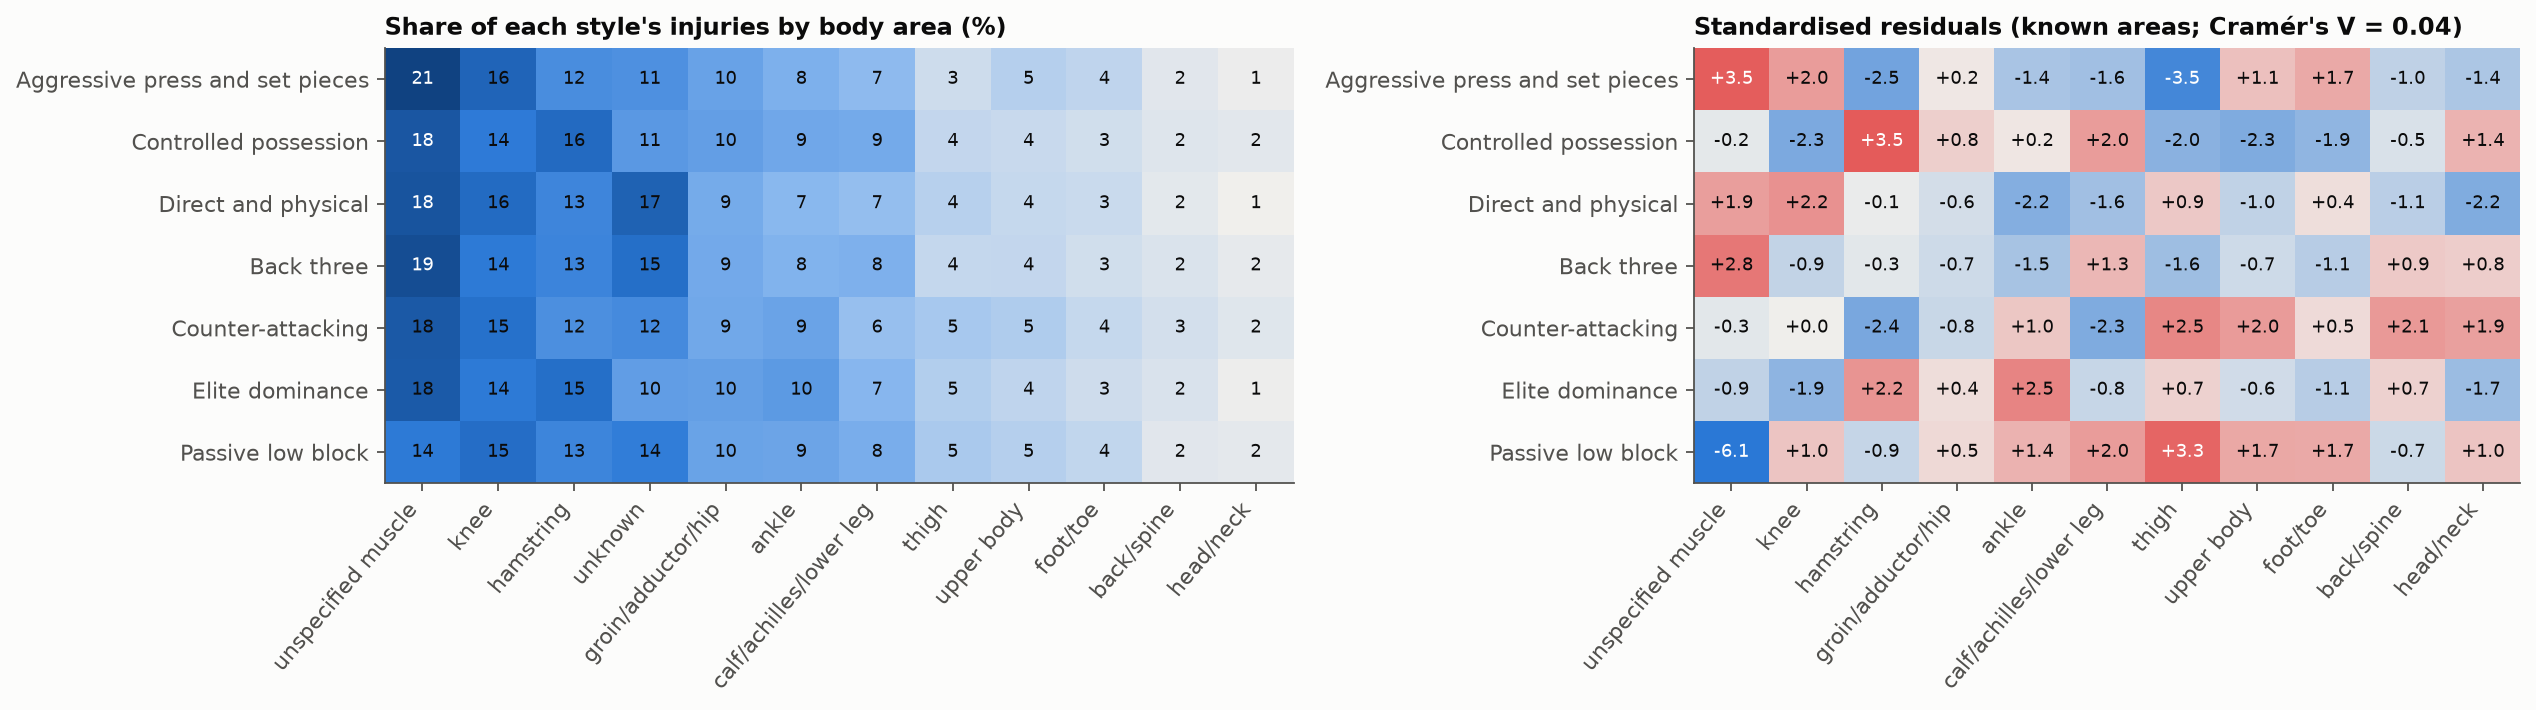

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
im = axes[0].imshow(100 * area_share.to_numpy(), cmap=SEQUENTIAL, aspect="auto")
axes[0].set_title("Share of each style's injuries by body area (%)", loc="left")
axes[1].imshow(residuals.to_numpy(), cmap=DIVERGING, vmin=-4, vmax=4, aspect="auto")
axes[1].set_title(f"Standardised residuals (known areas; Cramér's V = {cramers_v:.2f})", loc="left")
for ax, data, fmtv in [(axes[0], 100 * area_share, "{:.0f}"), (axes[1], residuals, "{:+.1f}")]:
    ax.set_xticks(range(data.shape[1]), data.columns, rotation=50, ha="right")
    ax.set_yticks(range(data.shape[0]), data.index)
    ax.grid(False)
    vals = data.to_numpy()
    for (i, j), v in np.ndenumerate(vals):
        dark = (v > 18) if ax is axes[0] else abs(v) > 3
        ax.text(j, i, fmtv.format(v), ha="center", va="center", fontsize=8, color="white" if dark else INK)
fig.tight_layout()
area_fig = save(fig, "05_body_areas_by_style.png")

### Within each league

Leagues label injuries differently (e.g. *unspecified muscle* is 29% of La Liga injuries but 7% of Premier League
ones), so a style common in one league could look different only because of labelling. For each body area: the
style's share **within a league** relative to that league's share (1 = same), and in how many of the 5 leagues it is
above 1. A difference that holds in 4–5 leagues is a style pattern; one that flips between leagues is labelling.

In [8]:
AREAS_CHECK = [a for a in area_order if a != "unknown"][:7]
within_area = {}
for a in AREAS_CHECK:
    g = ps.groupby(["league", "cluster_name"])[[f"area: {a}", "injuries"]].sum()
    lg = ps.groupby("league")[[f"area: {a}", "injuries"]].sum()
    within_area[a] = (g[f"area: {a}"] / g.injuries).unstack().div(lg[f"area: {a}"] / lg.injuries, axis=0)[STYLE_ORDER]
leagues_above = pd.DataFrame({a: (t > 1).sum() for a, t in within_area.items()}).loc[STYLE_ORDER]
median_rel = pd.DataFrame({a: t.median() for a, t in within_area.items()}).loc[STYLE_ORDER].round(2)
display(within_area["hamstring"].round(2))
display(leagues_above.rename(columns=lambda c: f"{c}: leagues > 1"))
median_rel

cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
league,,,,,,,
Bundesliga,0.70,0.97,0.73,1.55,1.19,1.02,0.82
La Liga,0.92,1.05,0.97,0.42,1.15,1.15,1.09
Ligue 1,1.40,1.09,0.97,0.79,0.69,1.11,0.84
Premier League,0.82,1.04,1.23,0.94,0.98,1.01,0.97
Serie A,0.95,1.19,0.91,1.08,0.86,1.22,0.76


,unspecified muscle: leagues > 1,knee: leagues > 1,hamstring: leagues > 1,groin/adductor/hip: leagues > 1,ankle: leagues > 1,calf/achilles/lower leg: leagues > 1,thigh: leagues > 1
cluster_name,,,,,,,
Aggressive press and set pieces,0,2,1,2,0,2,1
Controlled possession,4,2,4,2,4,4,1
Direct and physical,1,5,1,3,2,0,3
Back three,3,2,2,1,2,4,0
Counter-attacking,1,3,2,4,3,1,4
Elite dominance,4,1,5,3,4,2,2
Passive low block,2,3,1,1,2,2,4


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh
cluster_name,,,,,,,
Aggressive press and set pieces,0.92,0.99,0.92,0.96,0.95,0.96,0.94
Controlled possession,1.08,0.98,1.05,0.99,1.02,1.09,0.75
Direct and physical,0.93,1.16,0.97,1.05,0.95,0.88,1.03
Back three,1.03,0.94,0.94,0.91,0.90,1.11,0.87
Counter-attacking,0.89,1.09,0.98,1.03,1.13,0.93,1.21
Elite dominance,1.19,0.88,1.11,1.11,1.04,1.00,0.74
Passive low block,0.89,1.00,0.84,0.96,0.97,0.99,1.26


## Step 5. Seasons

Injuries per player-season by season (raw, with 95% CIs), with the calendar events from the project notes, and how
the share of each style changed per league. Raw season rates mix real change with Transfermarkt's recording changes
(Phase 0: Premier League 2018-19 jump), so the per-league view and the share of unknown body areas are shown with it.

In [9]:
by_season = summarise(ps, "season_key")
unknown_share = (ps.groupby("season_key")["area: unknown"].sum() / ps.groupby("season_key").injuries.sum()).rename("unknown body area")
season_league = ps.groupby(["season_key", "league"]).apply(lambda d: d.injuries.sum() / len(d), include_groups=False).unstack()[LEAGUES]
style_share = pd.crosstab([clusters.league, clusters.season_key], clusters.cluster_name, normalize="index")[STYLE_ORDER]
display(fmt(by_season).join(unknown_share.round(3)))
display(season_league.round(3))

,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI),unknown body area
season_key,,,,,,,,,,
2014-15,2939,98,1741,0.592,0.398,29.1,0.480,0.88 (0.81–0.96),0.95 (0.86–1.07),0.157
2015-16,3008,98,1835,0.610,0.417,29.6,0.458,0.91 (0.82–0.99),0.97 (0.88–1.06),0.137
2016-17,3005,98,2124,0.707,0.487,33.4,0.470,1.05 (0.98–1.13),1.10 (1.01–1.19),0.123
2017-18,2997,98,2015,0.672,0.460,29.6,0.427,1.00 (0.93–1.07),0.97 (0.89–1.05),0.099
2018-19,2944,98,2298,0.781,0.526,33.0,0.423,1.16 (1.07–1.26),1.08 (1.00–1.16),0.138
2019-20,3032,98,2166,0.714,0.521,31.9,0.429,1.06 (0.98–1.15),1.05 (0.96–1.14),0.096
2020-21,3161,98,2072,0.655,0.481,26.3,0.396,0.97 (0.90–1.06),0.86 (0.78–0.95),0.156
2021-22,3233,98,1919,0.594,0.442,25.7,0.445,0.88 (0.81–0.96),0.85 (0.77–0.92),0.145
2022-23,3148,98,1934,0.614,0.445,28.1,0.471,0.92 (0.84–0.99),0.92 (0.85–1.00),0.142


league,Premier League,La Liga,Serie A,Bundesliga,Ligue 1
season_key,,,,,
2014-15,0.600,0.516,0.693,0.849,0.320
2015-16,0.505,0.654,0.776,0.783,0.356
2016-17,0.565,0.891,0.740,0.900,0.465
2017-18,0.567,0.773,0.753,0.926,0.354
2018-19,1.077,0.798,0.773,0.894,0.374
2019-20,0.899,0.677,0.816,0.765,0.392
2020-21,0.677,0.490,0.871,0.746,0.483
2021-22,0.501,0.473,0.862,0.663,0.456
2022-23,0.552,0.409,0.870,0.673,0.568


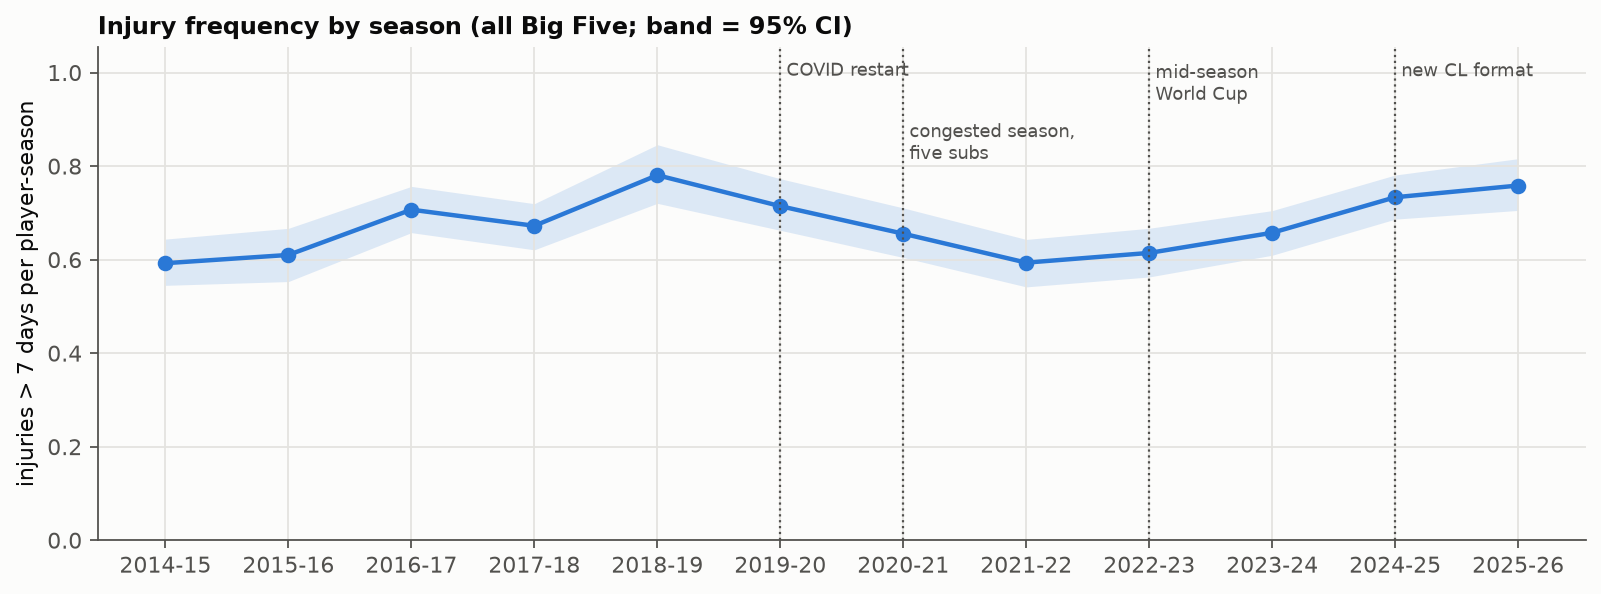

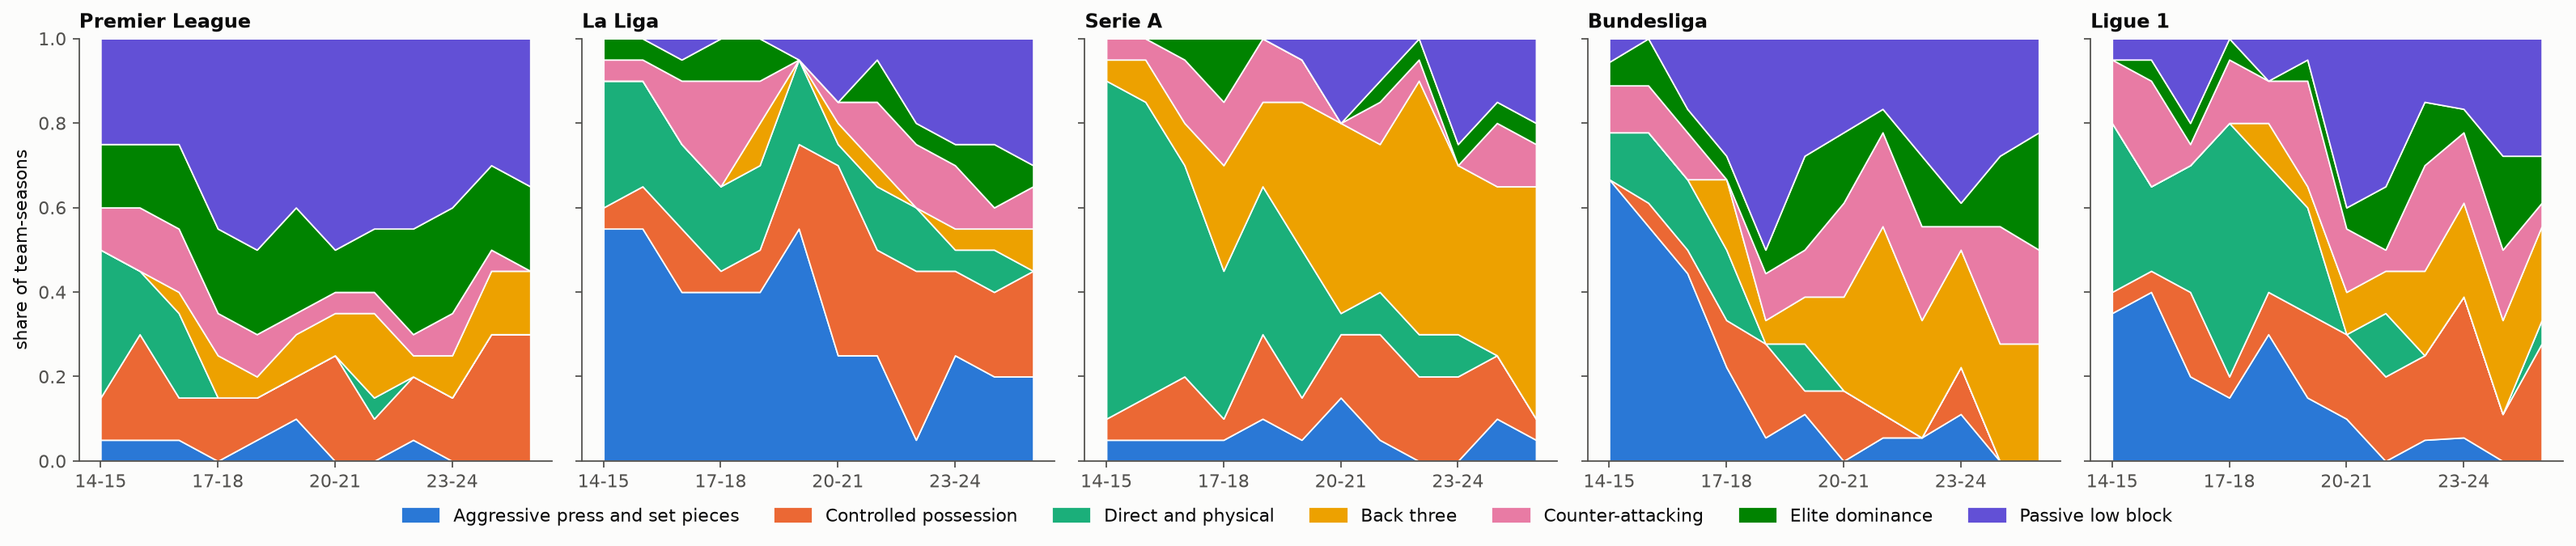

In [10]:
EVENTS = {"2019-20": "COVID restart", "2020-21": "congested season,\nfive subs", "2022-23": "mid-season\nWorld Cup",
          "2024-25": "new CL format"}
LABEL_Y = {"2019-20": 0.97, "2020-21": 0.85, "2022-23": 0.97, "2024-25": 0.97}  # stagger neighbouring labels
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(by_season))
ax.fill_between(x, by_season["injuries / player-season"] * by_season["RR low"] / by_season["RR"],
                by_season["injuries / player-season"] * by_season["RR high"] / by_season["RR"], color=SERIES[0], alpha=0.15, linewidth=0)
ax.plot(x, by_season["injuries / player-season"], color=SERIES[0], marker="o", markersize=6)
ax.set_xticks(x, by_season.index)
ax.set_ylabel("injuries > 7 days per player-season")
ax.set_ylim(0, by_season["injuries / player-season"].max() * 1.35)
for s, label in EVENTS.items():
    xi = list(by_season.index).index(s)
    ax.axvline(xi, color=MUTED, linewidth=1, linestyle=":")
    ax.text(xi + 0.05, ax.get_ylim()[1] * LABEL_Y[s], label, fontsize=8, color=MUTED, va="top")
ax.set_title("Injury frequency by season (all Big Five; band = 95% CI)", loc="left")
trend_fig = save(fig, "05_season_trend.png")

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, lg in zip(axes, LEAGUES):
    d = style_share.loc[lg].reindex(by_season.index).fillna(0)
    ax.stackplot(range(len(d)), d.T.to_numpy(), colors=SERIES[:len(STYLE_ORDER)], edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(lg, loc="left")
    ax.set_xticks(range(0, len(d), 3), [d.index[i][2:] for i in range(0, len(d), 3)])
    ax.set_ylim(0, 1)
    ax.grid(False)
axes[0].set_ylabel("share of team-seasons")
handles = [plt.Rectangle((0, 0), 1, 1, color=SERIES[i]) for i in range(len(STYLE_ORDER))]
fig.legend(handles, STYLE_ORDER, loc="lower center", ncol=len(STYLE_ORDER), frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
shares_fig = save(fig, "05_style_shares_by_league.png")

## Step 6. Leagues

Rates and body-area mix per league (raw: these differ partly because of recording), and the **style effect within
each league**: the RR of each style against its own league's average (the league-adjusted RR computed separately per
league). A pattern that holds in several leagues is more convincing than one carried by a single league.

In [11]:
by_league = summarise(ps, "league").loc[LEAGUES]
league_area = ps.groupby("league")[AREA_COLS].sum().loc[LEAGUES].rename(columns=lambda c: c[6:])[area_order]
league_area_share = league_area.div(league_area.sum(axis=1), axis=0)
within = summarise(ps, ["league", "cluster_name"])
rr_within = within["RR"].unstack()[STYLE_ORDER].loc[LEAGUES]
n_within = within["team-seasons"].unstack()[STYLE_ORDER].loc[LEAGUES]
display(fmt(by_league))
display((100 * league_area_share).round(1))
display(rr_within.round(2))
n_within

,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
league,,,,,,,,,
Premier League,7524,240,5151,0.685,0.451,36.2,0.512,1.00 (0.95–1.06),1.00 (0.94–1.06)
La Liga,7429,240,4451,0.599,0.402,26.9,0.448,1.00 (0.93–1.07),1.00 (0.93–1.06)
Serie A,7787,240,6410,0.823,0.608,30.4,0.371,1.00 (0.96–1.04),1.00 (0.95–1.05)
Bundesliga,6616,216,5227,0.790,0.593,37.7,0.474,1.00 (0.96–1.04),1.00 (0.95–1.05)
Ligue 1,7169,234,3342,0.466,0.334,21.5,0.452,1.00 (0.94–1.06),1.00 (0.93–1.07)


,unspecified muscle,knee,hamstring,unknown,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body,foot/toe,back/spine,head/neck
league,,,,,,,,,,,,
Premier League,6.6,16.4,19.0,13.7,9.8,10.5,8.6,3.4,3.9,3.9,2.3,1.8
La Liga,29.0,13.9,15.7,6.7,8.2,7.8,7.5,1.6,3.7,3.3,1.5,0.9
Serie A,20.3,12.3,13.0,20.4,7.9,6.6,7.7,3.4,3.5,2.2,1.8,1.1
Bundesliga,22.5,16.5,6.0,10.5,9.7,9.9,6.0,3.3,5.6,4.4,3.2,2.3
Ligue 1,7.4,15.4,12.6,9.2,12.7,9.8,8.8,13.0,4.1,3.6,2.0,1.6


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
league,,,,,,,
Premier League,1.04,1.09,0.80,0.87,0.77,1.24,0.94
La Liga,0.93,1.24,0.97,1.04,0.83,1.49,0.65
Serie A,0.99,1.07,0.90,1.06,0.92,0.90,1.14
Bundesliga,1.00,1.04,1.20,0.89,1.01,1.09,0.97
Ligue 1,1.01,1.22,0.70,1.03,0.83,1.64,0.97


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
league,,,,,,,
Premier League,7,41,15,21,19,46,91
La Liga,81,48,37,8,25,15,26
Serie A,14,33,68,76,21,9,19
Bundesliga,41,15,13,38,32,26,51
Ligue 1,35,38,45,23,35,18,40


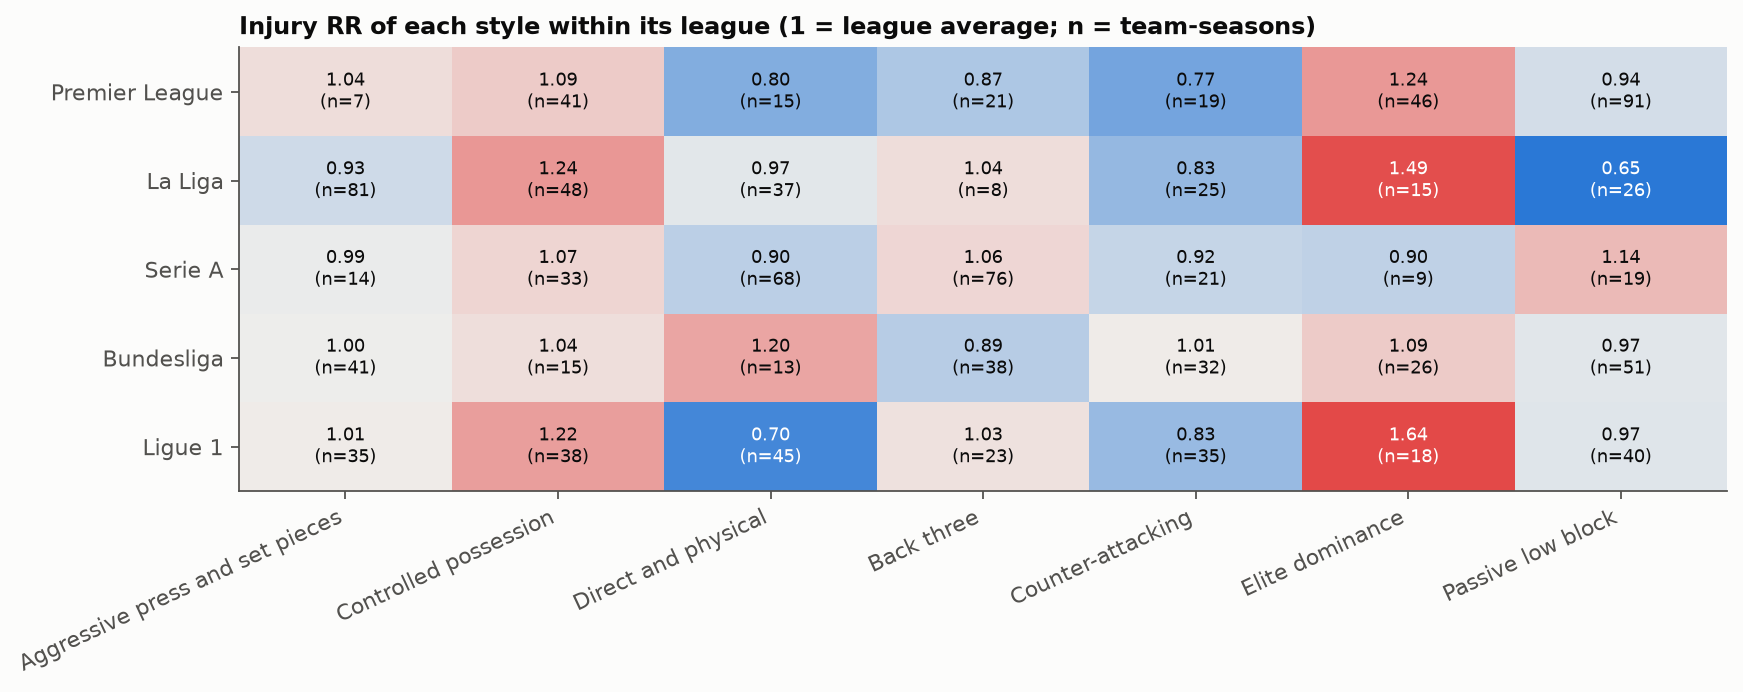

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.6))
vals = rr_within.to_numpy()
ax.imshow(np.log2(vals), cmap=DIVERGING, vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(STYLE_ORDER)), STYLE_ORDER, rotation=25, ha="right")
ax.set_yticks(range(len(LEAGUES)), LEAGUES)
ax.grid(False)
for (i, j), v in np.ndenumerate(vals):
    n = n_within.to_numpy()[i, j]
    ax.text(j, i, "–" if np.isnan(v) else f"{v:.2f}\n(n={int(n)})", ha="center", va="center", fontsize=8,
            color=INK if np.isnan(v) or abs(np.log2(v)) < 0.45 else "white")
ax.set_title("Injury RR of each style within its league (1 = league average; n = team-seasons)", loc="left")
league_fig = save(fig, "05_style_within_league.png")

## Step 7. Age and position

Styles differ in squad make-up (e.g. elite clubs field older players). If the style differences in step 3 were only
the age and position mix, they would shrink when the expected injuries come from **league × age band × position**
instead of league alone. Rates by age band and position are shown for context.

In [13]:
compare = pd.DataFrame({
    "RR, league-adjusted": by_style["RR"], "RR, league × age × position": by_style_lap["RR"],
    "days RR, league-adjusted": by_style["days RR"], "days RR, league × age × position": by_style_lap["days RR"],
}).round(2)
mix = pd.concat([ps.groupby("cluster_name").age.mean().round(1).rename("mean age"),
                 pd.crosstab(ps.cluster_name, ps.position, normalize="index").round(2)], axis=1).loc[STYLE_ORDER]
display(compare.join(mix))
display(fmt(summarise(ps.dropna(subset=["age_band"]), "age_band"))[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]])
fmt(summarise(ps.dropna(subset=["position"]), "position"))[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]]

,"RR, league-adjusted","RR, league × age × position","days RR, league-adjusted","days RR, league × age × position",mean age,Defender,Forward,Goalkeeper,Midfielder
cluster_name,,,,,,,,,
Aggressive press and set pieces,0.97,0.97,1.04,1.04,25.9,0.33,0.29,0.09,0.29
Controlled possession,1.14,1.16,1.06,1.07,25.7,0.34,0.28,0.08,0.30
Direct and physical,0.90,0.89,0.94,0.94,26.0,0.34,0.28,0.08,0.31
Back three,1.00,0.99,0.97,0.97,25.9,0.35,0.26,0.09,0.31
Counter-attacking,0.89,0.89,0.97,0.97,25.9,0.33,0.29,0.09,0.29
Elite dominance,1.25,1.29,1.08,1.11,25.4,0.34,0.25,0.09,0.31
Passive low block,0.95,0.93,0.97,0.95,26.2,0.34,0.29,0.09,0.29


,player-seasons,injuries / player-season,days lost / player-season,severe share
age_band,,,,
≤21,6166,0.365,19.6,0.519
22–25,10553,0.628,29.4,0.466
26–29,10525,0.774,34.4,0.432
30+,9260,0.814,34.5,0.426


,player-seasons,injuries / player-season,days lost / player-season,severe share
position,,,,
Defender,12362,0.755,34.5,0.448
Forward,10152,0.661,29.7,0.438
Goalkeeper,3127,0.418,21.3,0.511
Midfielder,10884,0.664,29.3,0.443


## Step 8. Team strength and workload

Styles partly follow team strength (Phase 4: eta² = 0.41 for points). **Strength:** the style RRs within each third
of teams by points per match: if a style's pattern holds among similarly strong teams, it is not just strength.
**Workload:** players of teams in the busiest third (share of matches on < 4 days' rest) vs the rest, within each
style: is congestion linked to injuries regardless of style?

In [14]:
rr_strength = summarise(ps, ["strength", "cluster_name"])["RR"].unstack()[STYLE_ORDER]
n_strength = summarise(ps, ["strength", "cluster_name"])["team-seasons"].unstack()[STYLE_ORDER]
ps["congestion"] = pd.qcut(ps.short_rest_share, 3, labels=["lightest third", "middle third", "busiest third"], duplicates="drop")
by_congestion = summarise(ps, "congestion")
rr_congestion = summarise(ps, ["congestion", "cluster_name"])["RR"].unstack()[STYLE_ORDER]
display(rr_strength.round(2))
display(n_strength)
display(fmt(by_congestion))
rr_congestion.round(2)

cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
strength,,,,,,,
middle third,1.05,1.01,0.87,0.93,0.92,1.05,0.97
stronger third,1.12,1.18,0.98,1.08,0.97,1.27,1.04
weaker third,0.82,1.18,0.89,0.98,0.86,0.78,0.92


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
strength,,,,,,,
middle third,68,43,64,60,46,4,86
stronger third,39,123,27,59,15,107,19
weaker third,71,9,87,47,71,3,122


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
congestion,,,,,,,,,
lightest third,12400,397,8048,0.649,0.521,29.7,0.455,0.94 (0.91–0.97),0.98 (0.94–1.03)
middle third,11970,386,7200,0.602,0.437,28.5,0.459,0.92 (0.88–0.96),0.95 (0.90–1.00)
busiest third,12155,387,9333,0.768,0.469,33.2,0.431,1.14 (1.10–1.18),1.07 (1.02–1.11)


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
congestion,,,,,,,
busiest third,1.21,1.16,0.99,1.05,1.02,1.26,1.04
lightest third,0.86,1.12,0.87,0.99,0.88,1.05,0.99
middle third,0.86,1.09,0.88,0.93,0.85,1.24,0.85


## Step 9. Fitness absences (secondary outcome)

*Fitness* absences are not injuries (Phase 2) but may show loss of conditioning. They are recorded almost only in
the Bundesliga (10.9 per 100 player-seasons vs ≤ 1.1 elsewhere), so they are compared by style **within the
Bundesliga**.

In [15]:
bl = ps[ps.league == "Bundesliga"]
fitness = bl.groupby("cluster_name").agg(player_seasons=("playerId", "size"), fitness_absences=("fitness_absences", "sum"))
fitness["per 100 player-seasons"] = (100 * fitness.fitness_absences / fitness.player_seasons).round(1)
fitness.loc[STYLE_ORDER]

,player_seasons,fitness_absences,per 100 player-seasons
cluster_name,,,
Aggressive press and set pieces,1237,142,11.5
Controlled possession,455,31,6.8
Direct and physical,403,61,15.1
Back three,1189,144,12.1
Counter-attacking,980,98,10.0
Elite dominance,804,99,12.3
Passive low block,1548,145,9.4


## Step 10. Sensitivity checks

The league-adjusted RR by style under each variation in the plan. A finding is robust if its direction holds in
every row. (Expected injuries are recomputed within each variant.)

In [16]:
def rr_variant(df: pd.DataFrame, count: str = "injuries") -> pd.Series:
    d = df.assign(injuries=df[count])
    d = add_expected(d, ["league"])
    t = summarise(d, "cluster_name")
    return t["RR"].reindex(STYLE_ORDER)


variants = {
    "main (> 7 days)": rr_variant(ps),
    "≥ 900 minutes only": rr_variant(ps[ps.minutes >= 900]),
    "severe only (> 28 days)": rr_variant(ps, "severe"),
    "> 3 days (adds mild)": rr_variant(ps.assign(more=ps.injuries + ps.mild_injuries), "more"),
    "multi-club players out": rr_variant(ps[ps.clubs_in_season == 1]),
    "COVID seasons out": rr_variant(ps[~ps.season_key.isin(COVID_SEASONS)]),
}
sensitivity = pd.DataFrame(variants).T.round(2)
direction = (np.sign(sensitivity - 1).nunique() == 1)
k4 = summarise(ps, "cluster_k4_name")
display(sensitivity)
print("same direction in every variant:", direction[direction].index.tolist())
fmt(k4)[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share", "RR (95% CI)", "days RR (95% CI)"]]

cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
main (> 7 days),0.97,1.14,0.90,1.00,0.89,1.25,0.95
≥ 900 minutes only,0.95,1.15,0.87,1.01,0.87,1.33,0.90
severe only (> 28 days),0.99,1.10,0.98,0.93,0.97,1.09,0.97
> 3 days (adds mild),0.97,1.16,0.86,1.01,0.87,1.31,0.93
multi-club players out,0.97,1.15,0.89,1.00,0.89,1.26,0.93
COVID seasons out,0.97,1.17,0.89,1.01,0.89,1.27,0.92


same direction in every variant: ['Aggressive press and set pieces', 'Controlled possession', 'Direct and physical', 'Counter-attacking', 'Elite dominance', 'Passive low block']


,player-seasons,injuries / player-season,days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
cluster_k4_name,,,,,,
Back three,6478,0.735,31.0,0.405,0.99 (0.95–1.03),0.97 (0.92–1.03)
Direct and physical,10674,0.604,28.0,0.459,0.93 (0.89–0.97),0.99 (0.94–1.04)
Dominant pressing,8015,0.798,34.0,0.426,1.21 (1.15–1.26),1.09 (1.03–1.14)
Passive low block,11358,0.614,30.0,0.485,0.93 (0.88–0.97),0.96 (0.91–1.01)


## Step 11. Report

In [17]:
sig = by_style[(by_style["RR low"] > 1) | (by_style["RR high"] < 1)]
sig_days = by_style[(by_style["days RR low"] > 1) | (by_style["days RR high"] < 1)]
cols = ["player-seasons", "team-seasons", "injuries", "injuries / player-season", "per 1,000 min", "days lost / player-season",
        "severe share", "RR (95% CI)", "days RR (95% CI)"]
text = [
    "# Phase 5: Injury analysis",
    "",
    f"Generated {date.today().isoformat()} by `notebooks/05_injury_analysis.ipynb`, where each step is shown with its checks.",
    "",
    "## Key numbers",
    "",
    f"- {len(ps):,} player-club-seasons, {int(ps.injuries.sum()):,} injuries > 7 days, {int(ps.days_lost.sum()):,} days lost.",
    f"- Styles whose injury RR CI excludes 1: " + (", ".join(f"{s} {r:.2f}" for s, r in sig["RR"].items()) or "none") + ".",
    f"- Styles whose days-lost RR CI excludes 1: " + (", ".join(f"{s} {r:.2f}" for s, r in sig_days["days RR"].items()) or "none") + ".",
    f"- Observed vs expected injuries across styles: chi² = {style_test[0]:.1f}, df = {style_test[1]}, p = {style_test[2]:.2g}.",
    f"- Body-area mix by style: chi² = {chi:.1f}, df = {dof_area}, p = {p_area:.2g}, Cramér's V = {cramers_v:.3f}.",
    f"- Same direction in every sensitivity check: {', '.join(direction[direction].index) or 'none'}.",
    "",
    "## 1. Injuries by style (k = 7)",
    "",
    md_table(fmt(by_style)[cols].rename_axis("style")),
    "",
    f"![Rates by style](figures/{style_fig})",
    "",
    "## 2. Body areas by style",
    "",
    md_table((100 * area_share).round(1).rename_axis("style")),
    "",
    "Standardised residuals (known areas):",
    "",
    md_table(residuals.round(1).rename_axis("style")),
    "",
    f"![Body areas](figures/{area_fig})",
    "",
    "Within each league (style's share relative to its league's share; median over leagues, and leagues above 1):",
    "",
    md_table(median_rel.rename_axis("style")),
    "",
    md_table(leagues_above.rename_axis("style")),
    "",
    "## 3. Seasons",
    "",
    md_table(fmt(by_season)[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]].join(unknown_share.round(3)).rename_axis("season")),
    "",
    f"![Season trend](figures/{trend_fig})",
    "",
    f"![Style shares](figures/{shares_fig})",
    "",
    "## 4. Leagues",
    "",
    md_table(fmt(by_league)[cols].rename_axis("league")),
    "",
    "Style RR within each league:",
    "",
    md_table(rr_within.round(2).rename_axis("league")),
    "",
    f"![Within league](figures/{league_fig})",
    "",
    "## 5. Age and position",
    "",
    md_table(compare.join(mix).rename_axis("style")),
    "",
    "## 6. Team strength and workload",
    "",
    "Style RR within thirds of team strength (points per match):",
    "",
    md_table(rr_strength.round(2).rename_axis("strength")),
    "",
    "By congestion (share of matches on < 4 days' rest, thirds over player-seasons):",
    "",
    md_table(fmt(by_congestion)[cols].rename_axis("congestion")),
    "",
    "## 7. Fitness absences (Bundesliga, secondary outcome)",
    "",
    md_table(fitness.loc[STYLE_ORDER].rename_axis("style")),
    "",
    "## 8. Sensitivity checks (injury RR by style)",
    "",
    md_table(sensitivity.rename_axis("variant")),
    "",
    "k = 4 robustness check:",
    "",
    md_table(fmt(k4)[cols].rename_axis("style (k = 4)")),
    "",
    "## 9. Outputs",
    "",
    f"- `data/{PHASE}/player_seasons.parquet`: the player-club-season table with style, strength, workload, age, position and injuries.",
    "",
]
(REPORTS_DIR / "05_injury_analysis.md").write_text("\n".join(text), encoding="utf-8")
print("wrote", REPORTS_DIR / "05_injury_analysis.md")

wrote /Users/mohammadshweiki/Downloads/coding-projects/football-injuries/reports/05_injury_analysis.md
